In [1]:
#####     Plot Pattern     #####
import numpy as np
from joblib import load
import rasterio
import warnings
rng = np.random.default_rng(seed=42)  # 随机数生成器（用于散点随机偏移）

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
lat, lon = np.arange(-90, 90.1, 1), np.arange(0, 360.1, 1)  # 经纬度网格

import _calGlobal
factor = 1e-7  # 单位换算系数 (MgC/ha -> PgC)
def getGlobal(x, **kwargs):
    return _calGlobal.getGlobalSum(x, factor=factor, **kwargs)

def flipImage(tiff: np.ndarray, shift=180) -> np.ndarray:
    """Flip latitude and shift longitude from original raster layout to 0-360° layout."""
    flipped = np.flip(tiff, axis=0)  # 纬度翻转
    shifted = np.roll(flipped, -shift, axis=1)  # 经度平移
    return shifted


In [2]:
### ----- Load ESACCI V7 / CMIP6 / Koppen ----- ###
ESAv7_data = np.load("./Data/AGBC_ESAv7.npz")
ESAv7_std = np.load("./Data/AGBCsd_ESAv7.npz")
ESAv7_data = {k.title(): flipImage(val.astype(np.float32)) for k, val in ESAv7_data.items()}
ESAv7_std = {k.title(): flipImage(val.astype(np.float32)) for k, val in ESAv7_std.items()}
print("ESACCI V7:", ESAv7_data.keys())

# Extract mean and std of ESACCI V7
ESA_data = ESAv7_data["Mean"].copy()
ESA_std = ESAv7_std["Mean"].copy()

# Load CMIP6 data
### cRoot Ratio 不再使用 0.8 填充，而是 pixel MME
CMIP_set = np.load("./Data/CMIP6_AGBC.npz")
modelNum = len(CMIP_set)  # 模型数量：30
modelNames = list(CMIP_set.keys())
# Original CMIP6 maps (N, lat, lon)
CMIP_list0 = [np.array(val, dtype=np.float32) for val in CMIP_set.values()]
CMIP_data0:np.ndarray = np.stack(CMIP_list0, axis=0)
print(f"CMIP Models: {modelNum}")
print(modelNames)

with rasterio.open("./Data/Koppen_2010.tif", "r") as src:
    Koppen = src.read(1).astype(np.float32)
    Koppen = flipImage(Koppen)

ValidMask = (Koppen > 0) & (ESA_data > 0)
Koppen[~ValidMask] = np.nan
ESA_data[~ValidMask] = np.nan
ESA_std[~ValidMask] = np.nan
CMIP_data0[:, ~ValidMask] = np.nan


ESACCI V7: dict_keys(['2010', '2011', '2012', '2015', 'Mean'])
CMIP Models: 30
['ACCESS-ESM1-5', 'BCC-CSM2-MR', 'BCC-ESM1', 'CanESM5', 'CESM2-FV2', 'CESM2-WACCM-FV2', 'CESM2-WACCM', 'CESM2', 'CMCC-CM2-SR5', 'CMCC-ESM2', 'CNRM-ESM2-1', 'E3SM-1-1-ECA', 'E3SM-1-1', 'EC-Earth3-CC', 'EC-Earth3-Veg-LR', 'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'IPSL-CM6A-LR-INCA', 'IPSL-CM6A-LR', 'KIOST-ESM', 'MPI-ESM-1-2-HAM', 'MPI-ESM1-2-LR', 'NorCPM1', 'NorESM2-LM', 'NorESM2-MM', 'SAM0-UNICON', 'TaiESM1', 'UKESM1-0-LL', 'UKESM1-1-LL']


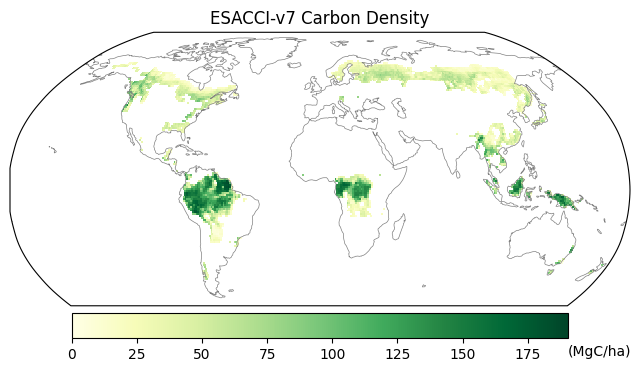

ESACCI-v7 AGC Density: 58.9 ± 41.0 MgC/ha
ESACCI-v7 Uncertainty: 10.6 ± 8.4 MgC/ha
ESACCI-v7 CoV: 17.7 ± 3.7%
 	Af	Am	Aw	BW	BS	Cs	Cw	Cf	Ds	Dw	Df	ET
Pixs:	467	264	401	1	31	25	156	217	29	294	1628	5
Unc:	22.8	21.3	10.6	1.5	4.0	17.7	10.2	10.6	11.3	4.8	6.4	7.4
CoV:	19.8	18.8	18.8	23.1	23.7	22.8	20.7	20.6	20.8	16.2	15.9	19.7


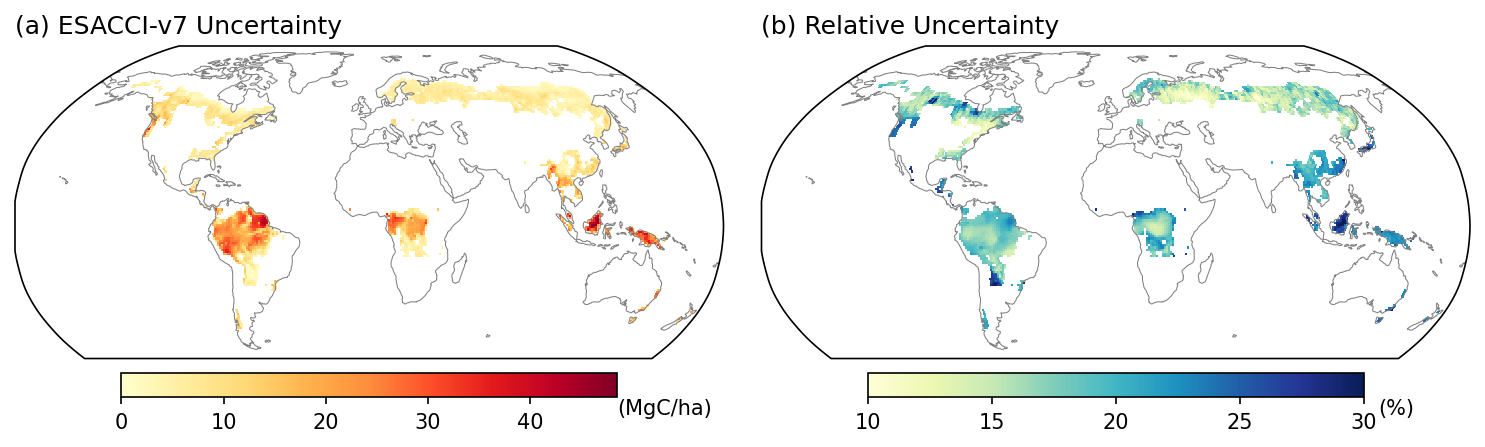

In [3]:
### ----- Reuse Tree Mask & Build Climate Zone Masks ----- ###

# Apply tree mask. Invalid pixels become NaN so getGlobal ignores them
TreeMask = load("./Data/Masks/treemask.joblib").astype(np.float32)
TreeMask[TreeMask == 0] = np.nan

ESA_datat = ESA_data * TreeMask     # ESACCI V7 data with tree mask
ESA_stdt = ESA_std * TreeMask       # ESACCI V7 uncertainty with tree mask
CMIP_datat = CMIP_data0 * TreeMask  # CMIP6 data with tree mask

### ----- Climate Zone Mask ----- ###
cliDict = {
    "Af": [1],  # Tropical rainforest
    "Am": [2],  # Tropical monsoon
    "Aw": [3],  # Tropical savanna
    "BW": [4, 5], # Arid desert
    "BS": [6, 7], # Semi-arid steppe
    "Cs": [8, 9, 10], # Temperate dry summer
    "Cw": [11, 12, 13], # Temperate dry winter
    "Cf": [14, 15, 16], # Temperate fully humid
    "Ds": [17, 18, 19, 20], # Boreal dry summer
    "Dw": [21, 22, 23, 24], # Boreal dry winter
    "Df": [25, 26, 27, 28], # Boreal fully humid
    "ET": [29],  # Polar tundra
    #"EF": [30]   # Polar frost. (excluded)
}
# f = fully humid, s = dry summer, w = dry winter
cliMask = [np.isin(Koppen, ids) for ids in cliDict.values()]

fig, ax = plt.subplots(1, 1, figsize=(8, 5), dpi=100, subplot_kw={"projection":ccrs.Robinson()})
img = ax.pcolormesh(lon, lat[30:], ESA_datat[30:], vmin=0, cmap="YlGn", transform=ccrs.PlateCarree(), shading="flat")
ax.coastlines(color="gray", linewidth=0.5)
cbar = plt.colorbar(img, ax=ax, orientation="horizontal", pad=0.02, shrink=0.8)
cbar.ax.text(1.0, -0.7, s="(MgC/ha)", transform=cbar.ax.transAxes)
ax.set_title("ESACCI-v7 Carbon Density")
plt.show(fig)
plt.close(fig)

### ----- ESACCI Uncertainty ----- ###
print(f"ESACCI-v7 AGC Density: {np.nanmean(ESA_datat):.1f} ± {np.nanstd(ESA_datat):.1f} MgC/ha")
print(f"ESACCI-v7 Uncertainty: {np.nanmean(ESA_stdt):.1f} ± {np.nanstd(ESA_stdt):.1f} MgC/ha")

cov = np.abs(ESA_stdt / (ESA_datat + 1e-6) * 100)
print(f"ESACCI-v7 CoV: {np.nanmean(cov):.1f} ± {np.nanstd(cov):.1f}%")

unc = [np.nanmean(ESA_stdt[m]) for m in cliMask]
print("\t".join([" "] + list(cliDict.keys())))
print("\t".join(["Pixs:"] + [f"{np.isfinite(ESA_datat[m]).sum()}" for m in cliMask]))
print("\t".join(["Unc:"] + [f"{i:.1f}" for i in unc]))
print("\t".join(["CoV:"] + [f"{np.nanmean(cov[m]):.1f}" for m in cliMask]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), dpi=150, subplot_kw={"projection":ccrs.Robinson()})

img = ax1.pcolormesh(lon, lat[30:], ESA_stdt[30:], vmin=0, cmap="YlOrRd",
                     transform=ccrs.PlateCarree(), shading="flat")
ax1.coastlines(color="gray", linewidth=0.5)
cbar = plt.colorbar(img, ax=ax1, orientation="horizontal", pad=0.02, shrink=0.7)
cbar.ax.text(1.0, -0.7, s="(MgC/ha)", transform=cbar.ax.transAxes)
ax1.set_title("(a) ESACCI-v7 Uncertainty", loc="left")

img = ax2.pcolormesh(lon, lat[30:], cov[30:], cmap="YlGnBu", vmin=10, vmax=30,
                     transform=ccrs.PlateCarree(), shading="flat")
ax2.coastlines(color="gray", linewidth=0.5)
cbar = plt.colorbar(img, ax=ax2, orientation="horizontal", pad=0.02, shrink=0.7)
cbar.ax.text(1.03, -0.7, s="(%)", transform=cbar.ax.transAxes)
ax2.set_title("(b) Relative Uncertainty", loc="left")

plt.tight_layout()
plt.show(fig)
plt.close(fig)


CCI-v7 Mean:  208.8 PgC   (302.8)
CMIP6 MME:  237.4 PgC ± 71.3 (421.9 ± 128.6)
 	Af	Am	Aw	BW	BS	Cs	Cw	Cf	Ds	Dw	Df	ET
CCI-v7:	67.33	36.70	27.84	0.01	0.51	1.74	8.61	11.72	1.20	6.82	46.16	0.16
CMIP6:	80.58	37.66	35.63	0.02	1.46	1.18	10.86	14.89	0.73	8.79	45.42	0.23
Diff:	13.25	0.96	7.79	0.02	0.95	-0.56	2.24	3.17	-0.47	1.97	-0.74	0.07
 	+19.7%	+2.6%	+28.0%	+346.4%	+184.0%	-32.0%	+26.0%	+27.0%	-39.0%	+28.9%	-1.6%	+42.5%


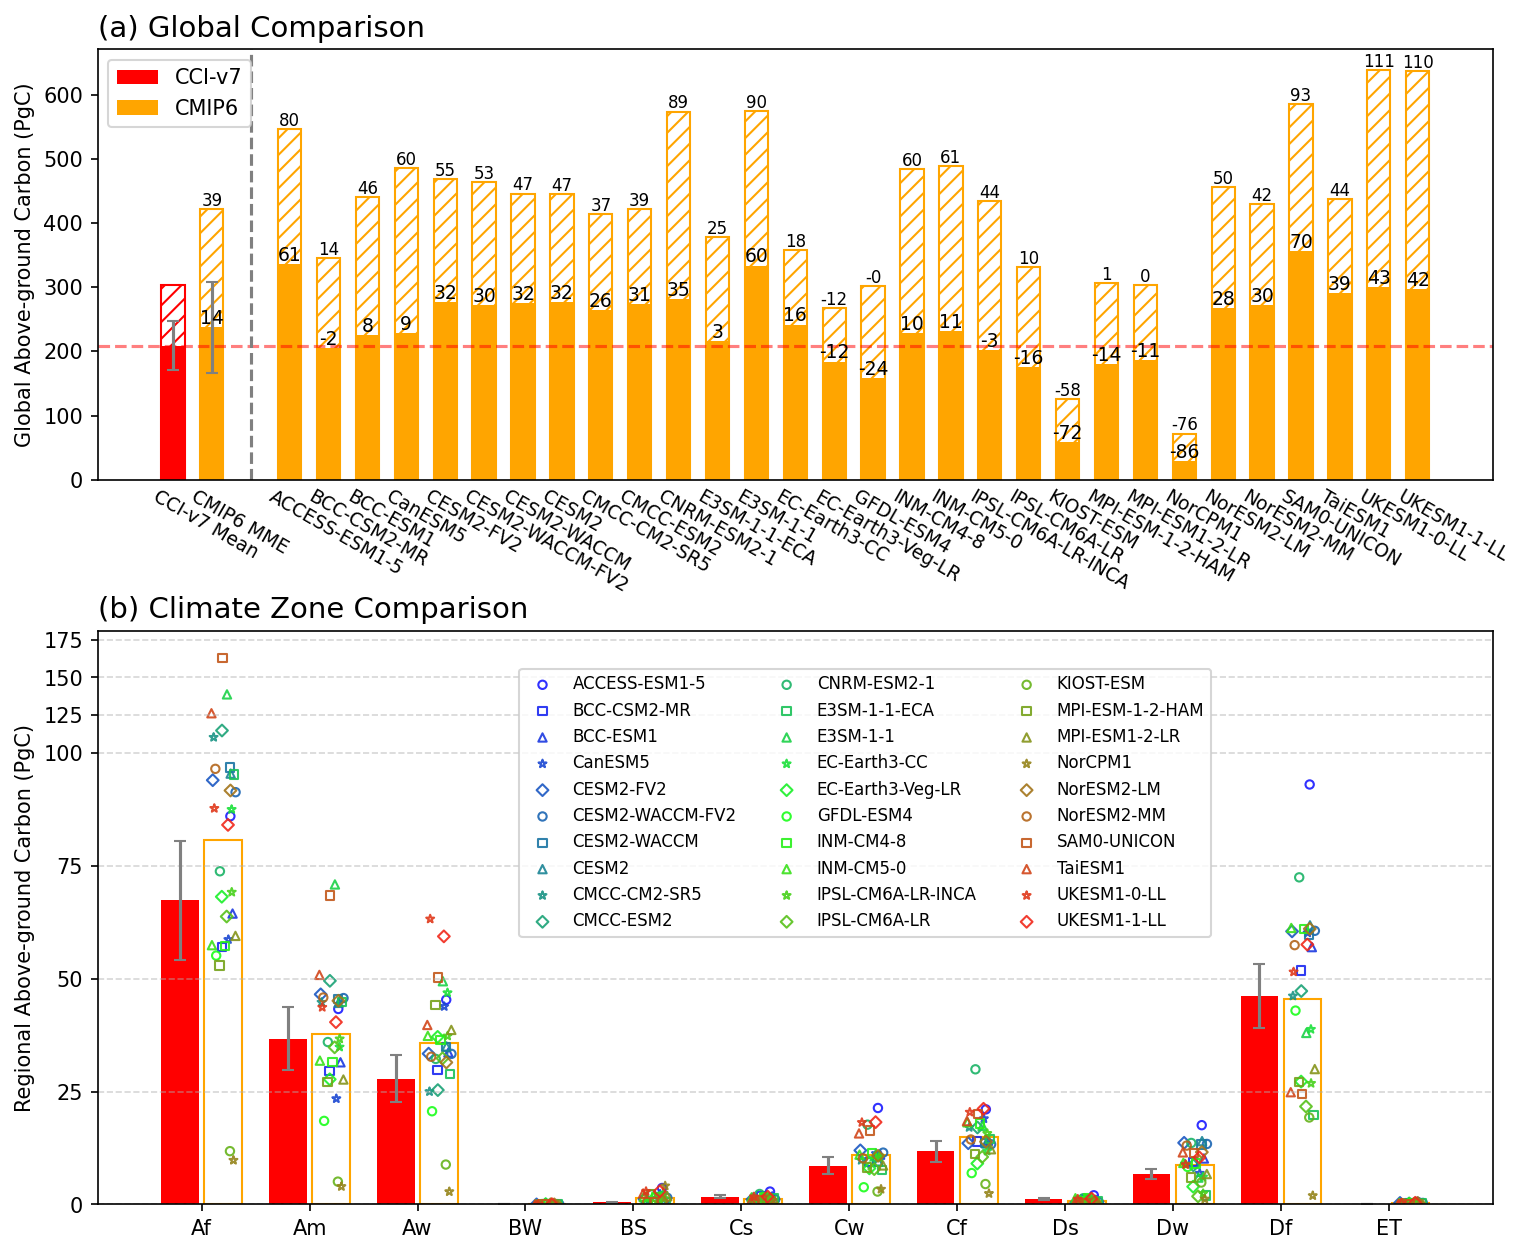

In [4]:
### ----- Global Comparison & Climate Zone Comparison ----- ###
fig, axs = plt.subplots(2, 1, figsize=(12, 10), dpi=150,
    gridspec_kw={"height_ratios":[3, 4], "hspace":0.3})
ax = axs[0]

### ESACCI V7 mean
esaSum0 = getGlobal(ESA_data)
esaSumt = getGlobal(ESA_datat)
ax.axhline(y=esaSumt, color="red", linestyle="--", alpha=0.5)
bar1_ = ax.bar([-2], [esaSum0], width=0.6, edgecolor="red", facecolor="none", hatch="///")
bar1t = ax.bar([-2], [esaSumt], width=0.6, color="red", label="CCI-v7")
ax.errorbar([-2], [esaSumt], yerr=[getGlobal(ESA_stdt)], color="gray", capsize=3, ls="none")

### CMIP6 models
x2 = np.arange(1, modelNum+1)
y20 = np.array(list(map(getGlobal, CMIP_data0)))
y2t = np.array(list(map(getGlobal, CMIP_datat)))
bar20 = ax.bar(x2, y20, width=0.6, edgecolor="orange", facecolor="none", hatch="///")
bar2t = ax.bar(x2, y2t, width=0.6, color="orange", label="CMIP6")

### CMIP6 multi-model mean
cmipMean0, cmipMeant = np.mean(y20), np.mean(y2t)
bar30 = ax.bar(-1, cmipMean0, width=0.6, edgecolor="orange", facecolor="none", hatch="///")
bar3t = ax.bar(-1, cmipMeant, width=0.6, color="orange")
ax.errorbar(-1, cmipMeant, yerr=np.std(y2t), color="gray", capsize=3, ls="none")

### Difference percentage relative to ESACCI V7
ax.axvline(x=0, color="gray", linestyle="--")
ax.text(-1, cmipMean0+5, f"{(cmipMean0-esaSum0)/esaSum0*100:.0f}", ha="center", fontsize=8)
ax.text(-1, cmipMeant+5, f"{(cmipMeant-esaSumt)/esaSumt*100:.0f}", ha="center", fontsize=9)
diff0 = (y20 - esaSum0) / esaSum0 * 100
difft = (y2t - esaSumt) / esaSumt * 100
for i in range(modelNum):
    ax.text(x2[i], y20[i]+5, f"{diff0[i]:.0f}", ha="center", fontsize=8)
for i in range(modelNum):
    ax.text(x2[i], y2t[i]+5, f"{difft[i]:.0f}", ha="center", fontsize=9)
shift = 0.6

ax.set_xticks([-2-shift,-1-shift]+list(x2-shift),
              labels=["CCI-v7 Mean","CMIP6 MME"]+modelNames,
              rotation=-30, fontsize=9, ha="left")
ax.tick_params(axis="x", length=0)
ax.set_ylabel("Global Above-ground Carbon (PgC)")
ax.legend(loc="upper left")
ax.set_title("(a) Global Comparison", fontsize=14, loc="left")

print(f"CCI-v7 Mean:  {esaSumt:.1f} PgC   ({esaSum0:.1f})")
print(f"CMIP6 MME:  {cmipMeant:.1f} PgC ± {np.std(y2t):.1f} ({cmipMean0:.1f} ± {np.std(y20):.1f})")

### ---------- Climate Zone Comparison ---------- ###
CMIP_zone = [[] for _ in range(len(cliDict))] # [zone, model]
for CMIP_map in CMIP_datat:
    for i in range(len(cliMask)):
        temp = CMIP_map.copy()
        temp[~cliMask[i]] = np.nan
        CMIP_zone[i].append(getGlobal(temp))
CMIP_zone = np.array(CMIP_zone)

ax = axs[1]
x = np.arange(0, len(cliDict))

### Climate Zone mean
y1 = [getGlobal(ESA_datat, mask=mask) for mask in cliMask]
bar1 = ax.bar(x-0.2, y1, width=0.35, color="red")
stds = [getGlobal(ESA_stdt, mask=mask) for mask in cliMask]
ax.errorbar(x-0.2, y1, yerr=stds, color="gray", capsize=3, ls="none")

y2 = CMIP_zone.mean(axis=1)
bar2 = ax.bar(x+0.2, y2, width=0.35, facecolor="none", edgecolor="orange")

### Scatter all CMIP6 models
from matplotlib.colors import LinearSegmentedColormap
colors = [(0.1, 0.1, 1.), (0.1, 1., 0.1), (1., 0.1, 0.1)]
cmap = LinearSegmentedColormap.from_list("mycmap", colors)
markers = ['o', 's', '^', '*', 'D']
shift = rng.uniform(-0.12, 0.12, size=modelNum)  # 随机偏移避免重叠
for i in range(modelNum):
    color = cmap(i/modelNum, alpha=0.8)
    marker = markers[i%len(markers)]
    ax.scatter(x+0.2+shift[i], CMIP_zone[:,i], s=16, alpha=0.9,
        facecolor="none", edgecolor=color, marker=marker, label=modelNames[i])

ax.set_yscale("function", functions=(   # scale y-axis
    lambda x: np.where(x<=100, x, 100 + (x-100)/3),  # forward
    lambda y: np.where(y<=100, y, 100 + (y-100)*3),  # inverse
))
ax.legend(loc="center", bbox_to_anchor=(0.55, 0.7), ncol=3, fontsize=8)
ax.set_ylabel("Regional Above-ground Carbon (PgC)")
ax.set_xticks(x, labels=cliDict.keys())
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ax.set_title("(b) Climate Zone Comparison", fontsize=14, loc="left")

print("\t".join([" "] + list(cliDict.keys())))
print("\t".join(["CCI-v7:"] + [f"{i:.2f}" for i in y1]))
print("\t".join(["CMIP6:"] + [f"{i:.2f}" for i in y2]))
print("\t".join(["Diff:"] + [f"{j-i:.2f}" if i!=0 else "--" for i,j in zip(y1,y2)]))
print("\t".join([" "] + [f"{(j-i)/i*100:+.1f}%" if i!=0 else "--" for i,j in zip(y1,y2)]))

plt.show(fig)  # fig 1
plt.close(fig)


C:\Users\Admin\AppData\Local\Temp\ipykernel_24732\4082870595.py:29: RuntimeWarning: Mean of empty slice
  data = np.nanmean(CMIP_datat, axis=0)  # MME Mean


Major Agreement: 1646 / 3518


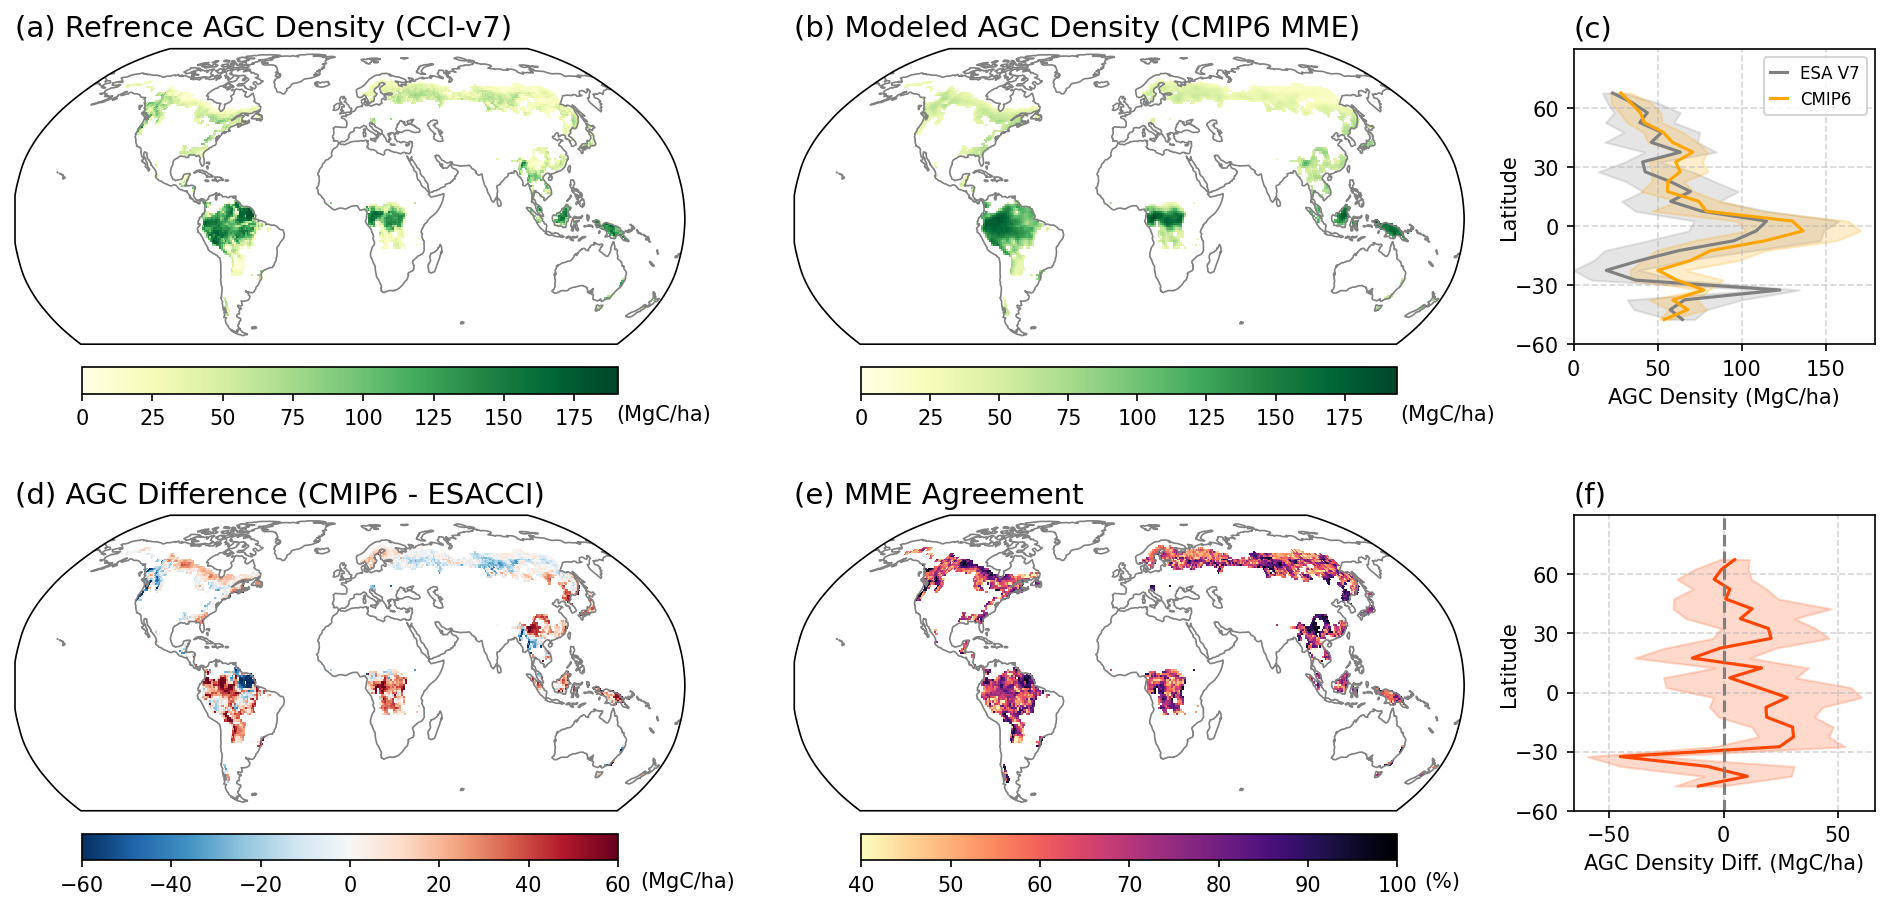

In [5]:
### ---------- Global Map ---------- ###
from matplotlib.gridspec import GridSpec

def get_lat_mean(arr:np.ndarray, group=3) -> tuple:
    """Return latitude-binned mean and standard deviation."""
    lat_num, lon_num = arr.shape
    if lat_num % group != 0:
        raise ValueError("lat %% group != 0")
    with warnings.catch_warnings(action="ignore"):
        reshaped = arr.reshape(lat_num//group, -1)
        mean, std = np.nanmean(reshaped, axis=-1), np.nanstd(reshaped, axis=-1)
    return mean, std

fig = plt.figure(figsize=(16, 8), dpi=150)
gs = GridSpec(2, 3, fig, width_ratios=[1, 1, 0.45], hspace=0.02)

### Keep 60S to 90N
# ========== 上半部分子图 ========== #
### ESACCI V7 map.
ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.Robinson())
img1 = ax1.pcolormesh(lon, lat[30:], ESA_datat[30:], vmin=0, cmap="YlGn",
                      transform=ccrs.PlateCarree(), shading="flat")
ax1.coastlines(color="gray", linewidth=0.8)
ax1.set_title("(a) Refrence AGC Density (CCI-v7)", fontsize=14, loc="left")
cbar = fig.colorbar(img1, ax=ax1, orientation="horizontal", shrink=0.8, pad=0.05)
cbar.ax.text(190, -1, s="(MgC/ha)")

### CMIP6 multi-model mean map
data = np.nanmean(CMIP_datat, axis=0)  # MME Mean
ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.Robinson())
img2 = ax2.pcolormesh(lon, lat[30:], data[30:], vmin=0, cmap="YlGn",
                      transform=ccrs.PlateCarree(), shading="flat")
ax2.coastlines(color="gray", linewidth=0.8)
ax2.set_title("(b) Modeled AGC Density (CMIP6 MME)", fontsize=14, loc="left")
cbar = fig.colorbar(img2, ax=ax2, orientation="horizontal", shrink=0.8, pad=0.05)
cbar.ax.text(195, -1, s="(MgC/ha)")

### Latitude profiles
group = 5
lat_range = np.arange(-60+group/2, 90, group)
ESA_lat, ESA_lat_std = get_lat_mean(ESA_datat[30:], group=group)
CMIP_lat, CMIP_std = get_lat_mean(data[30:], group=group)

ax3 = fig.add_subplot(gs[0, 2])
xmin, xmax = ESA_lat-ESA_lat_std, ESA_lat+ESA_lat_std
ax3.plot(ESA_lat, lat_range, linestyle="-", color="gray", label="ESA V7")
ax3.fill_betweenx(lat_range, xmin, xmax, color="gray", alpha=0.2)
xmin, xmax = CMIP_lat-CMIP_std, CMIP_lat+CMIP_std
ax3.plot(CMIP_lat, lat_range, linestyle="-", color="orange", label="CMIP6")
ax3.fill_betweenx(lat_range, xmin, xmax, color="orange", alpha=0.2)
pos1, pos3 = ax1.get_position(), ax3.get_position()
ax3.set_position([pos3.x0, pos1.y0, pos3.width, pos1.height])

ax3.set_ylim(-60, 90)
ax3.set_yticks(np.arange(-60, 61, 30))
ax3.set_ylabel("Latitude", labelpad=-2)
ax3.set_xlim(0, None)
ax3.set_xlabel("AGC Density (MgC/ha)")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend(loc="best", fontsize=8, handlelength=1)
ax3.set_title("(c)", fontsize=14, loc="left")

# ========== 下半部分子图 ========== #
### Absolute difference
diff = data - ESA_datat
ax4 = fig.add_subplot(gs[1, 0], projection=ccrs.Robinson())
img4 = ax4.pcolormesh(lon, lat[30:], diff[30:], vmin=-60, vmax=60, cmap="RdBu_r",
                      transform=ccrs.PlateCarree(), shading="flat")
ax4.coastlines(color="gray", linewidth=0.8)
ax4.set_title("(d) AGC Difference (CMIP6 - ESACCI)", fontsize=14, loc="left")
cbar = fig.colorbar(img4, ax=ax4, orientation="horizontal", shrink=0.8, pad=0.05)
cbar.ax.text(65, -1, s="(MgC/ha)")

### Sign agreement for model-observation differences
agree = ((CMIP_datat - ESA_datat) * diff) > 0  # (N, lat, lon)
agree = np.mean(agree, axis=0) * 100
agree[np.isnan(diff)] = np.nan
ax5 = fig.add_subplot(gs[1, 1], projection=ccrs.Robinson())
img5 = ax5.pcolormesh(lon, lat[30:], agree[30:], vmin=40, vmax=100, cmap="magma_r",
                      transform=ccrs.PlateCarree(), shading="flat")
ax5.coastlines(color="gray", linewidth=0.8)
ax5.set_title("(e) MME Agreement", fontsize=14, loc="left")
cbar = fig.colorbar(img5, ax=ax5, orientation="horizontal", shrink=0.8, pad=0.05)
cbar.ax.text(103, -1, s="(%)")

agree_66 = np.sum(agree > 66.7)
print(f"Major Agreement: {agree_66} / {np.sum(~np.isnan(agree))}")

### Latitude profile of the difference
ax6 = fig.add_subplot(gs[1, 2])
diff_lat, diff_std = get_lat_mean(diff[30:], group=group)
ax6.plot(diff_lat, lat_range, linestyle="-", color="orangered")
xmin, xmax = diff_lat-diff_std, diff_lat+diff_std
ax6.fill_betweenx(lat_range, xmin, xmax, color="orangered", alpha=0.2)
pos4, pos6 = ax4.get_position(), ax6.get_position()
ax6.set_position([pos6.x0, pos4.y0, pos6.width, pos4.height])

ax6.set_ylim(-60, 90)
ax6.set_yticks(np.arange(-60, 61, 30))
ax6.set_ylabel("Latitude", labelpad=-2)
ax6.set_xlabel("AGC Density Diff. (MgC/ha)")
ax6.axvline(x=0, color="gray", linestyle="--")
ax6.grid(True, linestyle="--", alpha=0.5)
ax6.set_title("(f)", fontsize=14, loc="left")

plt.show(fig)  # fig 3
plt.close(fig)


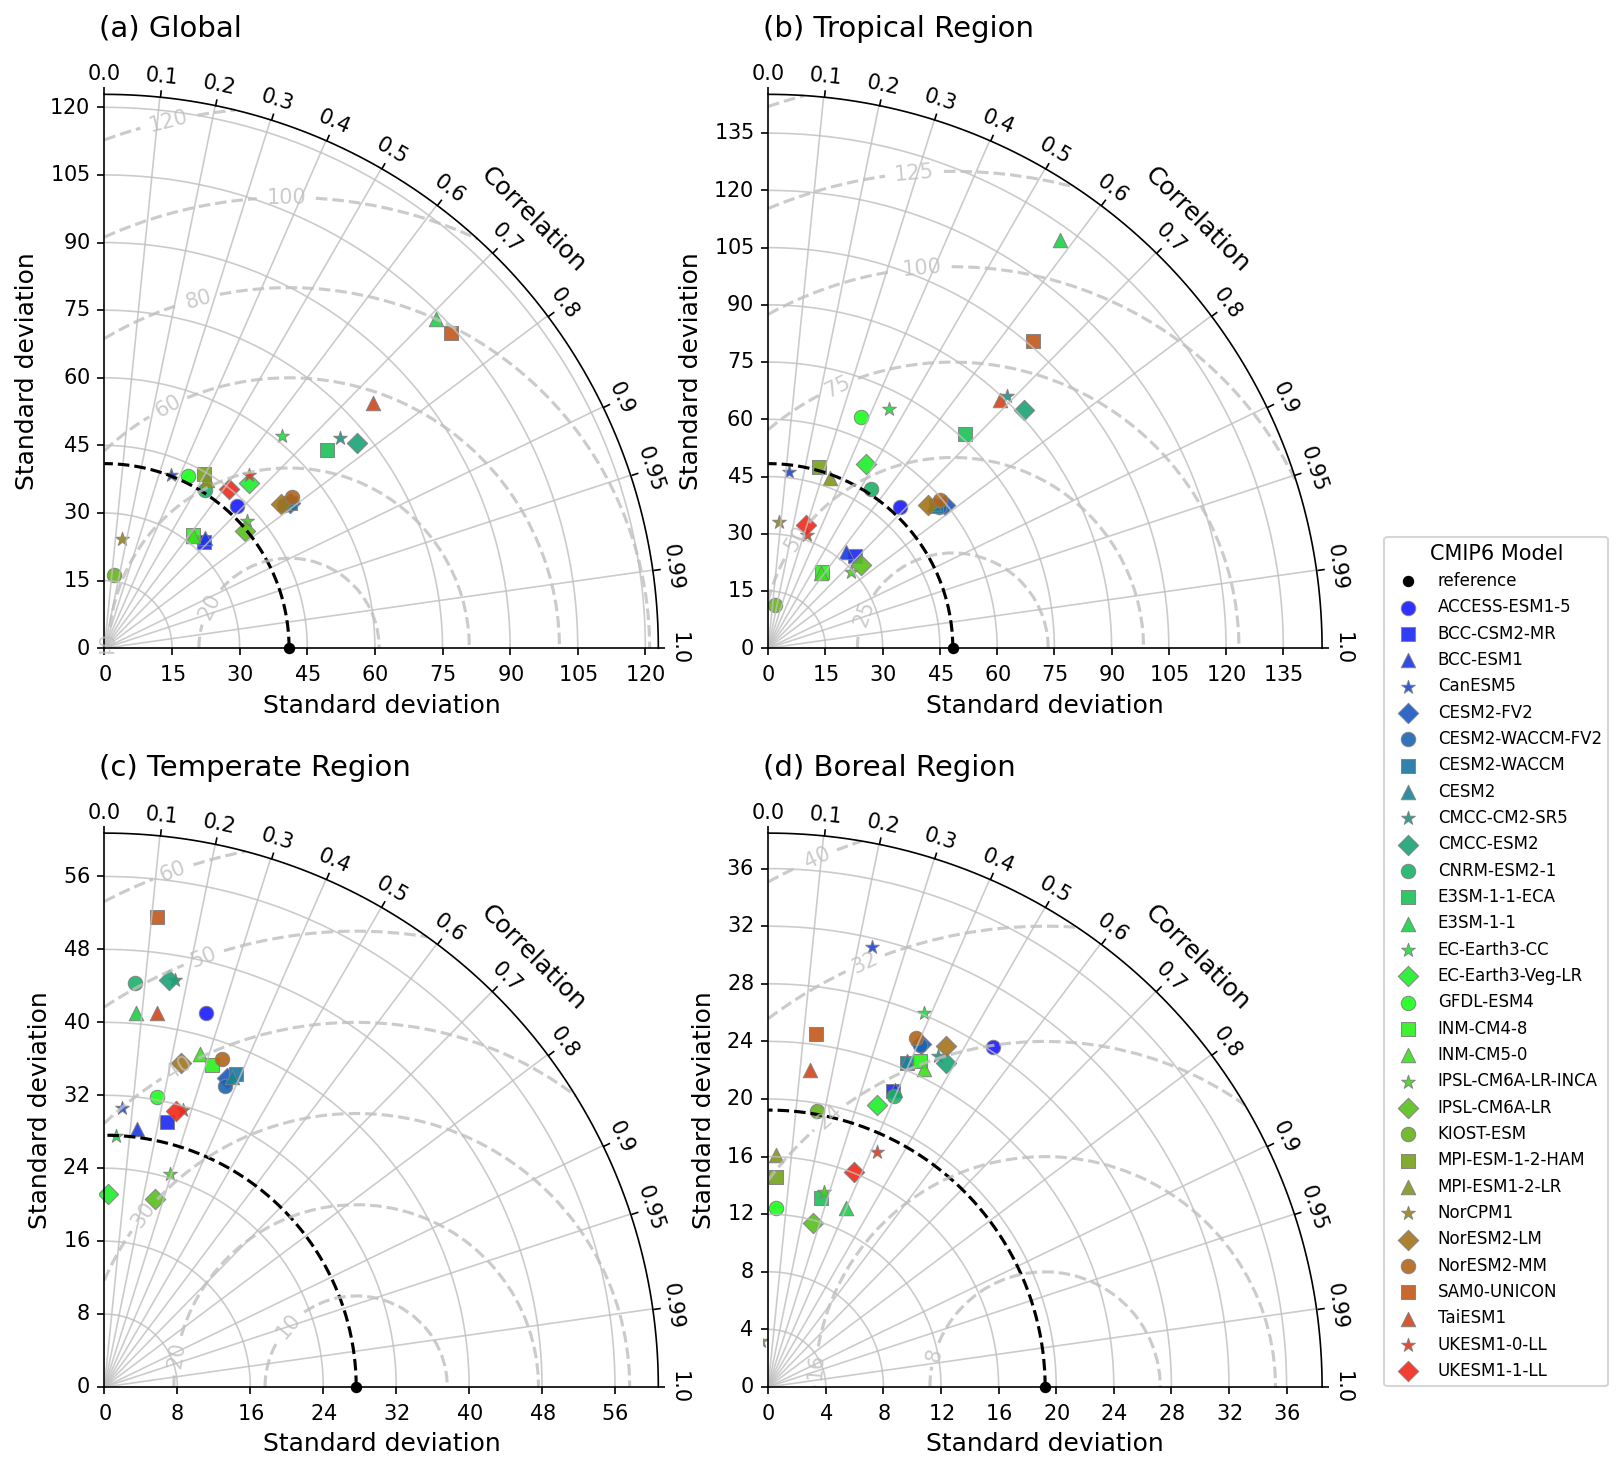

In [6]:
### ---------- Taylor Diagram ---------- ###
from _taylorDiagram import TaylorDiagram

def plot_diagram(figure, rect=111, stdrange=3., mask=None, subtitle=""):
    if mask is not None:
        mask0 = (ESA_datat > 0) & mask
    else:
        mask0 = ESA_datat > 0
    refstd = np.std(ESA_datat[mask0])

    # Plot Taylor Diagram
    diagram = TaylorDiagram(refstd, figure, rect, std_range=(0, stdrange))
    diagram.add_grid()
    diagram.add_RMSD(levels=6)
    ax:plt.Axes = diagram._ax
    # Add model samples
    for i in range(modelNum):
        data = CMIP_datat[i]
        mask1 = mask0 & (data > 0)
        color = cmap(i/modelNum, alpha=0.8)
        marker = markers[i%len(markers)]
        stddev = np.nanstd(data[mask1])
        corrcoef = np.corrcoef(data[mask1], ESA_datat[mask1])[0, 1]
        diagram.add_sample(
            stddev, corrcoef, label=modelNames[i],
            marker=marker, facecolor=color, edgecolor="gray",
            linewidth=0.5, s=48, alpha=0.9,
            )
    if subtitle:
        ax.set_title(subtitle, fontsize=14, pad=25, loc="left")
    return diagram

# "Af", "Am", "Aw", "BW", "BS",
# "Cs", "Cw", "Cf", "Ds", "Dw", "Df", "ET", "EF"
fig = plt.figure(figsize=(9, 10), dpi=150)
dia = plot_diagram(fig, 221, subtitle="(a) Global")

mask_zone = cliMask[0] | cliMask[1] | cliMask[2]
dia = plot_diagram(fig, 222, mask=mask_zone, subtitle="(b) Tropical Region")

mask_zone = cliMask[5] | cliMask[6] | cliMask[7]
dia = plot_diagram(fig, 223, mask=mask_zone, stdrange=2.2, subtitle="(c) Temperate Region")

mask_zone = cliMask[8] | cliMask[9] | cliMask[10]
dia = plot_diagram(fig, 224, mask=mask_zone, stdrange=2, subtitle="(d) Boreal Region")

fig_handles = dia.get_handles()  # 其中第一个是 reference
fig.legend(fig_handles, ["reference"]+list(modelNames), title="CMIP6 Model",
           loc="lower left", bbox_to_anchor=(1.0, 0.05), fontsize=8)

plt.tight_layout()
plt.show(fig)  # fig 4
plt.close(fig)


Model Num: 30,  Land Model: 15


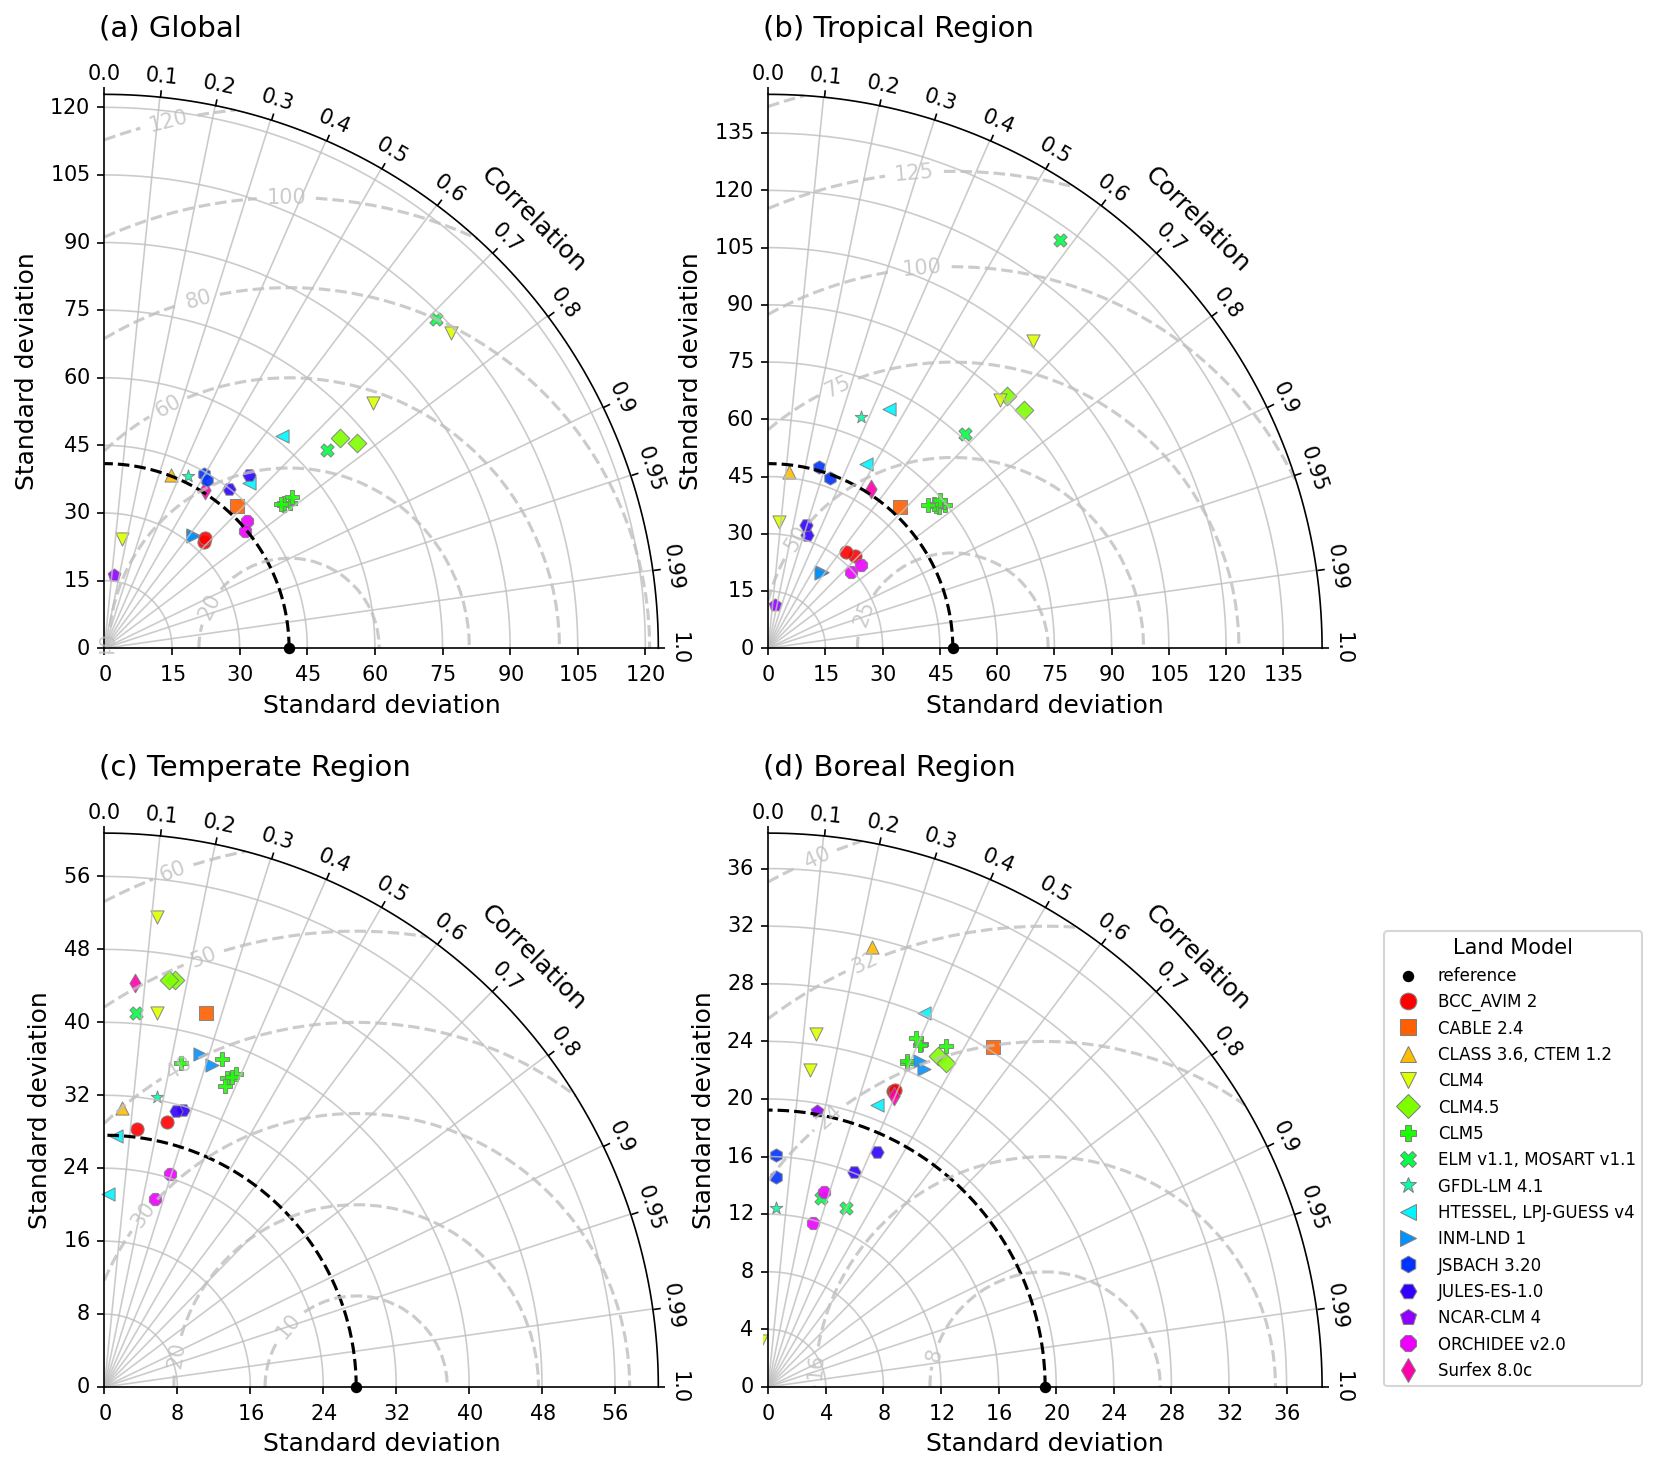

In [7]:
### ---------- Taylor Diagram by Land Model ---------- ###
from matplotlib.lines import Line2D

LandModel = np.asarray([
    "CABLE 2.4",
    "BCC_AVIM 2",
    "BCC_AVIM 2",
    "CLASS 3.6, CTEM 1.2",
    "CLM5",
    "CLM5",
    "CLM5",
    "CLM5",
    "CLM4.5",
    "CLM4.5",
    "Surfex 8.0c",
    "ELM v1.1, MOSART v1.1",
    "ELM v1.1, MOSART v1.1",
    "HTESSEL, LPJ-GUESS v4",
    "HTESSEL, LPJ-GUESS v4",
    "GFDL-LM 4.1",
    "INM-LND 1",
    "INM-LND 1",
    "ORCHIDEE v2.0",
    "ORCHIDEE v2.0",
    "NCAR-CLM 4",
    "JSBACH 3.20",
    "JSBACH 3.20",
    "CLM4",
    "CLM5",
    "CLM5",
    "CLM4",
    "CLM4",
    "JULES-ES-1.0",
    "JULES-ES-1.0",
])

unique = np.unique(LandModel)
print(f"Model Num: {len(LandModel)},  Land Model: {len(unique)}")

if len(LandModel) != len(modelNames):
    raise ValueError(f"LandModel length ({len(LandModel)}) does not match modelNames length ({len(modelNames)}).")

land_cmap = plt.get_cmap("hsv")(np.linspace(0, 0.9, len(unique)))
land_markers = ["o", "s", "^", "v", "D", "P", "X", "*", "<", ">", "h", "H", "p", "8", "d"]
land_model_style = {
    land_model: {
        "color": land_cmap[i],
        "marker": land_markers[i % len(land_markers)],
    }
    for i, land_model in enumerate(unique)
}

def plot_diagram_sup(figure, rect=111, stdrange=3., mask=None, subtitle=""):
    if mask is not None:
        mask0 = (ESA_datat > 0) & mask
    else:
        mask0 = ESA_datat > 0
    refstd = np.std(ESA_datat[mask0])

    diagram = TaylorDiagram(refstd, figure, rect, std_range=(0, stdrange))
    diagram.add_grid()
    diagram.add_RMSD(levels=6)
    ax: plt.Axes = diagram._ax

    for i in range(modelNum):
        data = CMIP_datat[i]
        mask1 = mask0 & (data > 0)
        land_model = LandModel[i]
        style = land_model_style[land_model]
        stddev = np.nanstd(data[mask1])
        corrcoef = np.corrcoef(data[mask1], ESA_datat[mask1])[0, 1]
        diagram.add_sample(
            stddev, corrcoef, label=land_model,
            marker=style["marker"], facecolor=style["color"],
            edgecolor="gray", linewidth=0.5, s=40, alpha=0.9,
        )
    if subtitle:
        ax.set_title(subtitle, fontsize=14, pad=25, loc="left")
    return diagram

fig = plt.figure(figsize=(9, 10), dpi=150)
dia = plot_diagram_sup(fig, 221, subtitle="(a) Global")

mask_zone = cliMask[0] | cliMask[1] | cliMask[2]
dia = plot_diagram_sup(fig, 222, mask=mask_zone, subtitle="(b) Tropical Region")

mask_zone = cliMask[5] | cliMask[6] | cliMask[7]
dia = plot_diagram_sup(fig, 223, mask=mask_zone, stdrange=2.2, subtitle="(c) Temperate Region")

mask_zone = cliMask[8] | cliMask[9] | cliMask[10]
dia = plot_diagram_sup(fig, 224, mask=mask_zone, stdrange=2, subtitle="(d) Boreal Region")

land_handles = [dia.get_handles()[0]] + [
    Line2D([0], [0], marker=land_model_style[land_model]["marker"], color="white",
           label=land_model, markerfacecolor=land_model_style[land_model]["color"],
           markeredgecolor="gray", markeredgewidth=0.5, markersize=8)
    for land_model in unique
]
fig.legend(land_handles, ["reference"]+list(unique), title="Land Model",
           loc="lower left", bbox_to_anchor=(1.0, 0.05), fontsize=8)

plt.tight_layout()
plt.show(fig)
plt.close(fig)
